# 2.Tạo bảng mục tiêu một dòng cho mỗi giờ quan sát

In [1]:
from pathlib import Path

import pandas as pd

# Hỗ trợ chạy từ thư mục gốc dự án hoặc thư mục notebooks/.
project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_path = project_dir / "data" / "Metro_Interstate_Traffic_Volume.csv"

if not data_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy CSV tại {data_path}")

# Giữ nguyên chuỗi "None" như trong notebook validation.
df_raw = pd.read_csv(data_path, keep_default_na=False)
print(f"Số dòng gốc: {len(df_raw):,}")

Số dòng gốc: 48,204


In [2]:
# Tạo bảng riêng để kiểm tra, giữ nguyên df_raw.
target_rows = df_raw[["date_time", "traffic_volume"]].copy()
target_rows["date_time"] = pd.to_datetime(
    target_rows["date_time"],
    format="%Y-%m-%d %H:%M:%S",
    errors="raise",
)

# Dừng nếu có mốc thiếu hoặc không nằm đúng đầu giờ.
timestamps = target_rows["date_time"]
if timestamps.isna().any() or not timestamps.eq(timestamps.dt.floor("h")).all():
    raise ValueError("Có timestamp bị thiếu hoặc không nằm đúng đầu giờ.")

# Mỗi giờ phải có đúng một giá trị lưu lượng khác biệt.
target_counts = target_rows.groupby("date_time")["traffic_volume"].nunique()
conflicting_times = target_counts[target_counts.ne(1)]

print(f"Số giờ có mục tiêu không nhất quán: {len(conflicting_times):,}")
if not conflicting_times.empty:
    display(conflicting_times.head())
    raise ValueError("Hãy kiểm tra các giờ trên trước khi gộp.")

Số giờ có mục tiêu không nhất quán: 0


## Tạo bảng một dòng mỗi giờ và xem kết quả

In [3]:
# Các cặp timestamp–lưu lượng lặp đã được kiểm tra ở cell trước.
hourly_target = (
    target_rows.drop_duplicates()
    .sort_values("date_time")
    .reset_index(drop=True)
)

print("Kích thước bảng:", hourly_target.shape)
print("Timestamp duy nhất:", hourly_target["date_time"].is_unique)
print("Đã sắp xếp theo thời gian:", hourly_target["date_time"].is_monotonic_increasing)
print(f"Số dòng dư đã bỏ: {len(df_raw) - len(hourly_target):,}")
display(hourly_target.head())

Kích thước bảng: (40575, 2)
Timestamp duy nhất: True
Đã sắp xếp theo thời gian: True
Số dòng dư đã bỏ: 7,629


,date_time,traffic_volume
0,2012-10-02 09:00:00,5545
1,2012-10-02 10:00:00,4516
2,2012-10-02 11:00:00,4767
3,2012-10-02 12:00:00,5026
4,2012-10-02 13:00:00,4918


**Nhận xét**

- Không phát hiện giờ nào có nhiều giá trị `traffic_volume` khác nhau.
- Bảng `hourly_target` có 40.575 dòng, mỗi timestamp xuất hiện một lần
  và được sắp xếp theo thời gian.
- Có 7.629 bản ghi lặp theo cặp `date_time` và `traffic_volume`
  được loại khi tạo bảng này. CSV gốc và `df_raw` vẫn giữ đủ
  48.204 dòng để dùng khi gộp dữ liệu thời tiết.

# 3.Gộp thời tiết theo giờ

## Chuẩn bị bản sao dữ liệu thời tiết
Tạo bản sao `weather_rows` từ các cột thời tiết trong `df_raw` và
gắn lại `date_time` đã được kiểm tra ở Bước 02. Bản sao này được
chuẩn bị để gộp các bản ghi thời tiết cùng giờ.

- Đánh dấu `temp = 0 K` là thiếu vì giá trị này không phù hợp với
  nhiệt độ môi trường.
- Tạm đánh dấu `rain_1h = 9831.3` lúc 17:00 ngày 11/07/2016 là thiếu
  vì đây là giá trị cực lớn và nguyên nhân chưa được xác minh.
- Bỏ khoảng trắng đầu/cuối và chuyển các nhãn thời tiết về chữ thường
  để những cách viết như `Sky is Clear` và `sky is clear` được xử lý
  như cùng một nhãn.

Các thao tác chỉ áp dụng trên bản sao. Việc gộp theo giờ được thực hiện
ở cell kế tiếp.

In [4]:
weather_numeric_cols = ["temp", "rain_1h", "snow_1h", "clouds_all"]
weather_label_cols = ["weather_main", "weather_description"]

weather_rows = df_raw[weather_numeric_cols + weather_label_cols].copy()

# Dùng lại timestamp đã parse và kiểm tra ở Bước 02.
weather_rows["date_time"] = target_rows["date_time"]

# Đánh dấu hai giá trị đã ghi nhận trong validation trước khi gộp.
# Nếu một giờ không còn giá trị hợp lệ, kết quả của giờ đó sẽ là NaN.
weather_rows["temp"] = weather_rows["temp"].mask(weather_rows["temp"].eq(0))
weather_rows["rain_1h"] = weather_rows["rain_1h"].mask(
    weather_rows["date_time"].eq(pd.Timestamp("2016-07-11 17:00:00"))
    & weather_rows["rain_1h"].eq(9831.3)
)

# Thống nhất khoảng trắng và cách viết hoa của các nhãn thời tiết.
for col in weather_label_cols:
    weather_rows[col] = weather_rows[col].str.strip().str.lower()

## Gộp theo giờ và kiểm tra kết quả

In [5]:
# Với mỗi cột số, tính median trên các giá trị phân biệt trong cùng giờ.
# Một số đo xuất hiện ở nhiều dòng nhãn chỉ được tính một lần.
hourly_weather_numeric = (
    weather_rows.groupby("date_time")[weather_numeric_cols]
    .agg(lambda values: values.drop_duplicates().median())
)

# Giữ tập nhãn của từng cột, sắp xếp để kết quả tái lập được.
hourly_weather_labels = (
    weather_rows.groupby("date_time")[weather_label_cols]
    .agg(lambda labels: " | ".join(sorted(set(labels) - {""})))
)

hourly_weather = (
    hourly_weather_numeric.join(hourly_weather_labels)
    .reset_index()
)

# Đối chiếu từng timestamp với bảng mục tiêu, kể cả thứ tự.
assert hourly_weather["date_time"].is_unique
assert hourly_weather["date_time"].equals(hourly_target["date_time"])

print("Kích thước bảng thời tiết:", hourly_weather.shape)
print("Timestamp khớp hoàn toàn với bảng mục tiêu")
print("Số giờ còn thiếu theo cột số:")
print(hourly_weather[weather_numeric_cols].isna().sum())

# Xem một giờ đã biết có nhiều nhãn thời tiết trong notebook validation.
display(
    hourly_weather.loc[
        hourly_weather["date_time"].eq(pd.Timestamp("2012-10-10 07:00:00"))
    ]
)

Kích thước bảng thời tiết: (40575, 7)
Timestamp khớp hoàn toàn với bảng mục tiêu
Số giờ còn thiếu theo cột số:
temp          10
rain_1h        1
snow_1h        0
clouds_all     0
dtype: int64


,date_time,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description
178,2012-10-10 07:00:00,281.25,0.0,0.0,99.0,drizzle | rain,light intensity drizzle | light rain


# 4. Ghép bảng mục tiêu và bảng thời tiết theo date_time

## Ghép bảng mục tiêu và bảng thời tiết theo giờ

Ghép `hourly_target` với `hourly_weather` theo `date_time`. Kiểm tra
mỗi giờ xuất hiện một lần ở mỗi bảng và có dữ liệu từ cả hai phía.

In [6]:
# Ghép theo timestamp và báo lỗi nếu một bảng có khóa lặp.
hourly_data = hourly_target.merge(
    hourly_weather,
    on="date_time",
    how="outer",
    validate="one_to_one",
    indicator=True,
    sort=True,
)

# Kiểm tra xem có giờ nào chỉ xuất hiện ở một trong hai bảng.
print("Kết quả đối chiếu timestamp:")
print(hourly_data["_merge"].value_counts())

if not hourly_data["_merge"].eq("both").all():
    display(hourly_data.loc[hourly_data["_merge"].ne("both"),
                            ["date_time", "_merge"]].head(10))
    raise ValueError("Hai bảng chưa khớp đủ timestamp.")

# Bỏ cột kiểm tra tạm sau khi xác nhận tất cả timestamp đều khớp.
hourly_data = hourly_data.drop(columns="_merge")

print("Kích thước bảng sau ghép:", hourly_data.shape)
print("Số giờ thiếu nhiệt độ và lượng mưa:")
print(hourly_data[["temp", "rain_1h"]].isna().sum())
display(hourly_data.head())

Kết quả đối chiếu timestamp:
_merge
both          40575
left_only         0
right_only        0
Name: count, dtype: int64
Kích thước bảng sau ghép: (40575, 8)
Số giờ thiếu nhiệt độ và lượng mưa:
temp       10
rain_1h     1
dtype: int64


,date_time,traffic_volume,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description
0,2012-10-02 09:00:00,5545,288.28,0.0,0.0,40.0,clouds,scattered clouds
1,2012-10-02 10:00:00,4516,289.36,0.0,0.0,75.0,clouds,broken clouds
2,2012-10-02 11:00:00,4767,289.58,0.0,0.0,90.0,clouds,overcast clouds
3,2012-10-02 12:00:00,5026,290.13,0.0,0.0,90.0,clouds,overcast clouds
4,2012-10-02 13:00:00,4918,291.14,0.0,0.0,75.0,clouds,broken clouds


**Nhận xét**

- Cả 40.575 timestamp đều có mặt trong hai bảng đầu vào.
  Bảng `hourly_data` có 40.575 dòng và 8 cột, mỗi giờ quan sát có một dòng.
- Sau khi ghép, `temp` vẫn thiếu ở 10 giờ và `rain_1h` vẫn thiếu ở 1 giờ,
  khớp với kết quả trước khi ghép. Các giá trị thiếu này chưa được điền.

# 5. Tạo đặc trưng ngày lễ theo ngày

Dùng nhãn sự kiện trong CSV gốc để tạo ánh xạ từ ngày sang tên sự kiện.
Gắn nhãn đó cho các giờ đã quan sát trong cùng ngày. Giá trị
`is_holiday = 0` biểu thị ngày không có nhãn sự kiện trong CSV.

## Tạo ánh xạ ngày sang tên sự kiện

In [7]:
# Lấy nhãn từ CSV gốc vì hourly_data chưa có cột holiday.
holiday_labels = df_raw["holiday"].str.strip()
has_event_label = holiday_labels.ne("None") & holiday_labels.ne("")

# Chuẩn hóa timestamp về đầu ngày để các giờ cùng ngày có chung khóa.
holiday_by_date = (
    pd.DataFrame({
        "date": target_rows["date_time"].dt.normalize(),
        "holiday_name": holiday_labels,
    })
    .loc[has_event_label]
    .drop_duplicates()
)

# Dừng nếu một ngày còn nhiều tên sau khi bỏ các cặp ngày–tên lặp.
conflicts = holiday_by_date["date"].duplicated(keep=False)
if conflicts.any():
    display(holiday_by_date.loc[conflicts].sort_values("date"))
    raise ValueError("Có ngày mang nhiều tên sự kiện.")

holiday_name_by_date = holiday_by_date.set_index("date")["holiday_name"]
print("Số ngày có nhãn sự kiện:", len(holiday_name_by_date))

Số ngày có nhãn sự kiện: 53


## Gắn đặc trưng và kiểm tra một ngày đã biết

In [8]:
# Tạo bảng mới, giữ hourly_data làm bảng đối chiếu của Bước 04.
hourly_with_holiday = hourly_data.copy()
observed_dates = hourly_with_holiday["date_time"].dt.normalize()

# Tra tên theo ngày và tạo cờ 0/1 từ kết quả tra.
event_names = observed_dates.map(holiday_name_by_date)
hourly_with_holiday["holiday_name"] = event_names.fillna("None")
hourly_with_holiday["is_holiday"] = event_names.notna().astype("int8")

# Xác nhận phép gắn nhãn giữ nguyên từng timestamp và thứ tự dòng.
assert hourly_with_holiday["date_time"].equals(hourly_data["date_time"])

print("Kích thước bảng:", hourly_with_holiday.shape)
print("Số ngày có ít nhất một giờ được gắn cờ:",
      observed_dates[hourly_with_holiday["is_holiday"].eq(1)].nunique())

# Kiểm tra Labor Day, gồm cả những giờ sau 00:00.
labor_day = hourly_with_holiday.loc[
    observed_dates.eq(pd.Timestamp("2018-09-03")),
    ["date_time", "holiday_name", "is_holiday"],
]
print("Số giờ quan sát trong ngày Labor Day:", len(labor_day))
display(labor_day.head(5))

Kích thước bảng: (40575, 10)
Số ngày có ít nhất một giờ được gắn cờ: 53
Số giờ quan sát trong ngày Labor Day: 24


,date_time,holiday_name,is_holiday
39903,2018-09-03 00:00:00,Labor Day,1
39904,2018-09-03 01:00:00,Labor Day,1
39905,2018-09-03 02:00:00,Labor Day,1
39906,2018-09-03 03:00:00,Labor Day,1
39907,2018-09-03 04:00:00,Labor Day,1


# 6. Chia train, validation và test theo thời gian

Chia bảng `hourly_with_holiday` theo thứ tự `date_time`. Khoảng 70%
số giờ quan sát đầu tiên được dùng cho train, 15% tiếp theo cho validation
và 15% cuối cho test. Tỷ lệ được tính theo số dòng sau khi gộp theo giờ.

Cell bên dưới kiểm tra mỗi timestamp chỉ thuộc một tập, train kết thúc
trước validation và validation kết thúc trước test. Bảng tổng hợp hiển thị
số dòng, tỷ lệ, mốc thời gian và số giờ thiếu `temp` hoặc `rain_1h` trong
từng tập. Các giá trị thiếu được giữ để xử lý sau khi đã xác định tập train.

In [9]:
# Sắp xếp theo thời gian và kiểm tra mỗi giờ chỉ có một dòng.
ordered_data = hourly_with_holiday.sort_values("date_time").reset_index(drop=True)
timestamps = ordered_data["date_time"]

assert timestamps.notna().all(), "Có timestamp bị thiếu."
assert timestamps.is_unique, "Có timestamp lặp."

# Lấy hai mốc cắt ở 70% và 85% số giờ quan sát, làm tròn xuống.
n_rows = len(ordered_data)
train_end = n_rows * 70 // 100
validation_end = n_rows * 85 // 100

train = ordered_data.iloc[:train_end].copy()
validation = ordered_data.iloc[train_end:validation_end].copy()
test = ordered_data.iloc[validation_end:].copy()

# Kiểm tra đủ dòng và thứ tự thời gian giữa ba tập.
assert all(len(part) > 0 for part in (train, validation, test))
assert len(train) + len(validation) + len(test) == n_rows
assert train["date_time"].max() < validation["date_time"].min()
assert validation["date_time"].max() < test["date_time"].min()

# Tóm tắt mốc chia và vị trí các giá trị thời tiết còn thiếu.
splits = {"train": train, "validation": validation, "test": test}

split_summary = pd.DataFrame(
    {
        "so_dong": len(part),
        "ty_le_pct": round(100 * len(part) / n_rows, 2),
        "tu_gio": part["date_time"].min(),
        "den_gio": part["date_time"].max(),
        "thieu_temp": part["temp"].isna().sum(),
        "thieu_rain_1h": part["rain_1h"].isna().sum(),
    }
    for part in splits.values()
).set_axis(splits.keys(), axis="index")

display(split_summary)

,so_dong,ty_le_pct,tu_gio,den_gio,thieu_temp,thieu_rain_1h
train,28402,70.0,2012-10-02 09:00:00,2017-05-10 04:00:00,10,1
validation,6086,15.0,2017-05-10 05:00:00,2018-01-19 14:00:00,0,0
test,6087,15.0,2018-01-19 15:00:00,2018-09-30 23:00:00,0,0


**Nhận xét**
- Đủ dòng và đúng thứ tự. Tổng cộng có 40.575 giờ quan sát. Train kết thúc trước validation, validation kết thúc trước test. Các kiểm tra timestamp duy nhất và thứ tự giữa các tập đều qua.
- Chênh một dòng giữa validation và test là đúng. Code làm tròn xuống tại hai mốc cắt 70% và 85%, rồi giao phần còn lại cho test.
- Các ô thời tiết thiếu đều nằm trong train. Train có 10 ô thiếu temp và 1 ô thiếu rain_1h. Validation và test có 0 ô thiếu ở hai cột này. Tổng số ô thiếu khớp với Bước 04. Các khoảng trống do thiếu cả bản ghi theo giờ vẫn được giữ nguyên.

# 7. Điền thiếu cho nhiệt độ và lượng mưa

Tính median nhiệt độ theo tháng và giờ trong ngày từ train. Nếu thiếu
nhóm tương ứng, dùng median nhiệt độ toàn train. Với lượng mưa, dùng
median toàn train.

Áp dụng cùng quy tắc cho cả ba tập và chỉ thay các ô đang thiếu.
Kiểm tra số ô trước và sau khi điền, đồng thời hiển thị các giờ đã điền
để đối chiếu.

## Tính thống kê từ train

In [10]:
# Dùng tháng và giờ làm khóa tra nhiệt độ trong tập train.
train_month = train["date_time"].dt.month.rename("month")
train_hour = train["date_time"].dt.hour.rename("hour")

temp_median_by_month_hour = (
    train.groupby([train_month, train_hour])["temp"]
    .median()
    .dropna()
)

# Tính giá trị dự phòng cho nhiệt độ và giá trị điền cho lượng mưa.
temp_median_train = train["temp"].median()
rain_median_train = train["rain_1h"].median()

assert pd.notna(temp_median_train), "Train không có nhiệt độ hợp lệ."
assert pd.notna(rain_median_train), "Train không có lượng mưa hợp lệ."

print("Số nhóm tháng–giờ có median nhiệt độ:", len(temp_median_by_month_hour))
print("Median nhiệt độ dự phòng từ train:", temp_median_train)
print("Median lượng mưa từ train:", rain_median_train)

Số nhóm tháng–giờ có median nhiệt độ: 288
Median nhiệt độ dự phòng từ train: 280.52
Median lượng mưa từ train: 0.0


## Điền thiếu và kiểm tra từng tập

In [11]:
weather_fill_cols = ["temp", "rain_1h"]
filled_splits = {}
fill_summary = []
fill_details = []

for split_name, part in splits.items():
    # Tạo bản sao để giữ các tập ban đầu làm bảng đối chiếu.
    filled = part.copy()
    missing_before = part[weather_fill_cols].isna()

    # Tra median theo tháng và giờ cho riêng các dòng thiếu nhiệt độ.
    temp_missing = missing_before["temp"]
    missing_times = part.loc[temp_missing, "date_time"]
    lookup_keys = pd.MultiIndex.from_arrays(
        [missing_times.dt.month, missing_times.dt.hour],
        names=["month", "hour"],
    )
    temp_lookup = temp_median_by_month_hour.reindex(lookup_keys)
    filled.loc[temp_missing, "temp"] = (
        temp_lookup.fillna(temp_median_train).to_numpy()
    )

    # Dùng cùng median lượng mưa từ train cho mọi tập.
    filled["rain_1h"] = filled["rain_1h"].fillna(rain_median_train)

    # Kiểm tra timestamp, mục tiêu và các giá trị đã quan sát.
    assert filled[["date_time", "traffic_volume"]].equals(
        part[["date_time", "traffic_volume"]]
    )
    for col in weather_fill_cols:
        observed = ~missing_before[col]
        assert filled.loc[observed, col].equals(part.loc[observed, col])

        changed = missing_before[col]
        fill_details.append(pd.DataFrame({
            "tap": split_name,
            "date_time": part.loc[changed, "date_time"],
            "cot": col,
            "gia_tri_dien": filled.loc[changed, col],
        }))

    missing_after = filled[weather_fill_cols].isna().sum()
    assert missing_after.eq(0).all(), f"{split_name} vẫn còn ô cần điền."

    filled_splits[split_name] = filled
    fill_summary.append({
        "tap": split_name,
        "temp_thieu_truoc": int(missing_before["temp"].sum()),
        "temp_thieu_sau": int(missing_after["temp"]),
        "rain_thieu_truoc": int(missing_before["rain_1h"].sum()),
        "rain_thieu_sau": int(missing_after["rain_1h"]),
        "temp_dung_median_du_phong": int(temp_lookup.isna().sum()),
    })

display(pd.DataFrame(fill_summary))
display(pd.concat(fill_details, ignore_index=True))

,tap,temp_thieu_truoc,temp_thieu_sau,rain_thieu_truoc,rain_thieu_sau,temp_dung_median_du_phong
0,train,10,0,1,0,0
1,validation,0,0,0,0,0
2,test,0,0,0,0,0


,tap,date_time,cot,gia_tri_dien
0,train,2014-01-31 03:00:00,temp,265.795
1,train,2014-01-31 04:00:00,temp,264.240
2,train,2014-01-31 05:00:00,temp,265.315
3,train,2014-01-31 06:00:00,temp,264.050
4,train,2014-02-02 03:00:00,temp,264.330
5,train,2014-02-02 04:00:00,temp,264.690
6,train,2014-02-02 05:00:00,temp,264.350
7,train,2014-02-02 06:00:00,temp,264.595
8,train,2014-02-02 07:00:00,temp,264.420
9,train,2014-02-02 08:00:00,temp,264.713


### Kiểm chứng giá trị điền nhiệt độ theo quan sát trước đó

Với mỗi giờ thiếu `temp` trong train, tìm giờ gần nhất trước đó có
nhiệt độ quan sát được. Hiển thị nhiệt độ này, khoảng cách tính theo
giờ và chênh lệch với median tháng–giờ đã dùng ở Bước 07. Bảng này
dùng để so sánh hai cách ước lượng.

In [12]:
# Lấy các giờ thiếu từ train trước khi điền.
temp_missing = train["temp"].isna()
temp_comparison = train.loc[temp_missing, ["date_time"]].copy()

# Lấy giá trị median tháng–giờ đã điền cho đúng các dòng đó.
temp_comparison["temp_median_thang_gio"] = (
    filled_splits["train"].loc[temp_missing, "temp"]
)

# Chỉ tra trong những giờ train có nhiệt độ quan sát được.
temp_observations = (
    train.loc[train["temp"].notna(), ["date_time", "temp"]]
    .rename(columns={
        "date_time": "gio_quan_sat_truoc",
        "temp": "temp_quan_sat_truoc",
    })
    .sort_values("gio_quan_sat_truoc")
)

# Ghép mỗi giờ thiếu với quan sát gần nhất nằm nghiêm ngặt trước nó.
temp_comparison = pd.merge_asof(
    temp_comparison.sort_values("date_time"),
    temp_observations,
    left_on="date_time",
    right_on="gio_quan_sat_truoc",
    direction="backward",
    allow_exact_matches=False,
)

temp_comparison["cach_bao_nhieu_gio"] = (
    temp_comparison["date_time"] - temp_comparison["gio_quan_sat_truoc"]
) / pd.Timedelta(hours=1)

temp_comparison["chenh_lech_K"] = (
    temp_comparison["temp_median_thang_gio"]
    - temp_comparison["temp_quan_sat_truoc"]
).round(3)

# Giữ đủ các giờ thiếu và kiểm tra hướng thời gian của các mốc tra được.
has_previous = temp_comparison["gio_quan_sat_truoc"].notna()
assert len(temp_comparison) == temp_missing.sum()
assert temp_comparison.loc[has_previous, "cach_bao_nhieu_gio"].gt(0).all()

display(temp_comparison)

,date_time,temp_median_thang_gio,gio_quan_sat_truoc,temp_quan_sat_truoc,cach_bao_nhieu_gio,chenh_lech_K
0,2014-01-31 03:00:00,265.795,2014-01-31 02:00:00,255.93,1.0,9.865
1,2014-01-31 04:00:00,264.240,2014-01-31 02:00:00,255.93,2.0,8.310
2,2014-01-31 05:00:00,265.315,2014-01-31 02:00:00,255.93,3.0,9.385
3,2014-01-31 06:00:00,264.050,2014-01-31 02:00:00,255.93,4.0,8.120
4,2014-02-02 03:00:00,264.330,2014-02-02 02:00:00,255.37,1.0,8.960
5,2014-02-02 04:00:00,264.690,2014-02-02 02:00:00,255.37,2.0,9.320
6,2014-02-02 05:00:00,264.350,2014-02-02 02:00:00,255.37,3.0,8.980
7,2014-02-02 06:00:00,264.595,2014-02-02 02:00:00,255.37,4.0,9.225
8,2014-02-02 07:00:00,264.420,2014-02-02 02:00:00,255.37,5.0,9.050
9,2014-02-02 08:00:00,264.713,2014-02-02 02:00:00,255.37,6.0,9.343


## Điền nhiệt độ bằng quan sát trước đó trong tối đa 6 giờ

Với mỗi ô `temp` thiếu, ưu tiên nhiệt độ quan sát gần nhất trước giờ đó
nếu khoảng cách không quá 6 giờ. Nếu không có quan sát đủ gần, dùng
median tháng–giờ từ train, hoặc median toàn train nếu thiếu nhóm tương ứng.

Chỉ cập nhật các ô `temp` vốn bị thiếu. Giữ nguyên giá trị điền `rain_1h`,
timestamp và lưu lượng.

In [13]:
# Dùng các quan sát trước khi điền để tra nhiệt độ.
# Giá trị đã điền ở giờ trước sẽ không được dùng làm quan sát.
observed_temp = (
    ordered_data.loc[ordered_data["temp"].notna(), ["date_time", "temp"]]
    .rename(columns={
        "date_time": "gio_quan_sat_truoc",
        "temp": "temp_quan_sat_truoc",
    })
    .sort_values("gio_quan_sat_truoc")
)

max_temp_age = pd.Timedelta(hours=6)
final_filled_splits = {}
temp_fill_audit = []

for split_name, original in splits.items():
    # Bắt đầu từ bảng đã điền bằng median ở Bước 07.
    updated = filled_splits[split_name].copy()
    missing = original["temp"].isna()

    if missing.any():
        missing_rows = original.loc[missing, ["date_time"]].sort_values("date_time")
        lookup = pd.merge_asof(
            missing_rows,
            observed_temp,
            left_on="date_time",
            right_on="gio_quan_sat_truoc",
            direction="backward",
            allow_exact_matches=False,
            tolerance=max_temp_age,
        )

        # Ghép theo timestamp để cập nhật đúng giờ.
        previous_by_time = lookup.set_index("date_time")["temp_quan_sat_truoc"]
        use_previous = missing & updated["date_time"].isin(
            previous_by_time.dropna().index
        )
        updated.loc[use_previous, "temp"] = (
            updated.loc[use_previous, "date_time"].map(previous_by_time)
        )

        lookup["tap"] = split_name
        lookup["cach_bao_nhieu_gio"] = (
            lookup["date_time"] - lookup["gio_quan_sat_truoc"]
        ) / pd.Timedelta(hours=1)
        lookup["temp_sau_khi_dien"] = lookup["date_time"].map(
            updated.set_index("date_time")["temp"]
        )
        temp_fill_audit.append(lookup)

    # Kiểm tra các giá trị quan sát và các cột khác được giữ nguyên.
    assert updated.loc[~missing, "temp"].equals(original.loc[~missing, "temp"])
    assert updated.drop(columns="temp").equals(
        filled_splits[split_name].drop(columns="temp")
    )
    assert updated["temp"].notna().all()
    final_filled_splits[split_name] = updated

audit = pd.concat(temp_fill_audit, ignore_index=True)
print("Số ô nhiệt độ được kiểm tra:", len(audit))
print("Số ô dùng quan sát trước đó:", audit["temp_quan_sat_truoc"].notna().sum())
display(audit)

Số ô nhiệt độ được kiểm tra: 10
Số ô dùng quan sát trước đó: 10


,date_time,gio_quan_sat_truoc,temp_quan_sat_truoc,tap,cach_bao_nhieu_gio,temp_sau_khi_dien
0,2014-01-31 03:00:00,2014-01-31 02:00:00,255.93,train,1.0,255.93
1,2014-01-31 04:00:00,2014-01-31 02:00:00,255.93,train,2.0,255.93
2,2014-01-31 05:00:00,2014-01-31 02:00:00,255.93,train,3.0,255.93
3,2014-01-31 06:00:00,2014-01-31 02:00:00,255.93,train,4.0,255.93
4,2014-02-02 03:00:00,2014-02-02 02:00:00,255.37,train,1.0,255.37
5,2014-02-02 04:00:00,2014-02-02 02:00:00,255.37,train,2.0,255.37
6,2014-02-02 05:00:00,2014-02-02 02:00:00,255.37,train,3.0,255.37
7,2014-02-02 06:00:00,2014-02-02 02:00:00,255.37,train,4.0,255.37
8,2014-02-02 07:00:00,2014-02-02 02:00:00,255.37,train,5.0,255.37
9,2014-02-02 08:00:00,2014-02-02 02:00:00,255.37,train,6.0,255.37


## Kiểm chứng quy tắc điền nhiệt độ bằng cách che các đoạn quan sát

Dùng 80% đầu của train để tính median tháng–giờ và 20% cuối để
kiểm chứng. Trong phần kiểm chứng, chọn các cửa sổ có đủ 7 giờ liên
tiếp với nhiệt độ quan sát được. Giữ giờ đầu làm thông tin quá khứ,
rồi giả lập thiếu 6 giờ tiếp theo.

So sánh sai số tuyệt đối của cách giữ quan sát trước đó và median
tháng–giờ theo độ dài khoảng thiếu và riêng các giờ 06:00–09:00.

## Chuẩn bị thống kê và các cửa sổ kiểm chứng

In [14]:
# Dùng train trước khi điền để các giá trị được che là quan sát thật.
temp_train = train[["date_time", "temp"]].sort_values("date_time").copy()
cut = len(temp_train) * 80 // 100
reference = temp_train.iloc[:cut].copy()
check = temp_train.iloc[cut:].reset_index(drop=True)

# Chỉ học median từ phần thời gian trước giai đoạn kiểm chứng.
reference["month"] = reference["date_time"].dt.month
reference["hour"] = reference["date_time"].dt.hour
check_medians = reference.groupby(["month", "hour"])["temp"].median()
fallback_median = reference["temp"].median()

assert pd.notna(fallback_median)

records = []

# Các cửa sổ tách rời nhau. Mỗi cửa sổ gồm 1 giờ trước và 6 giờ giả thiếu.
for start in range(0, len(check) - 6, 7):
    window = check.iloc[start:start + 7]

    # Chỉ kiểm chứng nơi có đủ quan sát và đúng 7 giờ liên tiếp.
    if window["temp"].isna().any():
        continue
    if not window["date_time"].diff().iloc[1:].eq(
        pd.Timedelta(hours=1)
    ).all():
        continue

    previous_temp = window.iloc[0]["temp"]

    for horizon in range(1, 7):
        row = window.iloc[horizon]
        timestamp = row["date_time"]
        median_estimate = check_medians.get(
            (timestamp.month, timestamp.hour), float("nan")
        )
        if pd.isna(median_estimate):
            median_estimate = fallback_median

        records.append({
            "date_time": timestamp,
            "cach_quan_sat_truoc_gio": horizon,
            "temp_thuc": row["temp"],
            "temp_giu_quan_sat_truoc": previous_temp,
            "temp_median_thang_gio": median_estimate,
        })

comparison = pd.DataFrame(records)
assert not comparison.empty, "Không tìm được cửa sổ đủ điều kiện."

print("Giai đoạn kiểm chứng:",
      check["date_time"].min(), "đến", check["date_time"].max())
print("Số cửa sổ hợp lệ:", len(comparison) // 6)
print("Số giờ được kiểm chứng:", len(comparison))

Giai đoạn kiểm chứng: 2016-09-12 12:00:00 đến 2017-05-10 04:00:00
Số cửa sổ hợp lệ: 776
Số giờ được kiểm chứng: 4656


## So sánh sai số

In [15]:
# Sai số tuyệt đối tính theo Kelvin.
comparison["sai_so_giu_truoc_K"] = (
    comparison["temp_giu_quan_sat_truoc"] - comparison["temp_thuc"]
).abs()
comparison["sai_so_median_K"] = (
    comparison["temp_median_thang_gio"] - comparison["temp_thuc"]
).abs()

# MAE là trung bình sai số tuyệt đối. Giá trị nhỏ hơn là tốt hơn.
by_horizon = comparison.groupby("cach_quan_sat_truoc_gio").agg(
    so_gio=("temp_thuc", "size"),
    MAE_giu_truoc_K=("sai_so_giu_truoc_K", "mean"),
    MAE_median_K=("sai_so_median_K", "mean"),
)

morning = comparison.loc[comparison["date_time"].dt.hour.between(6, 9)]
morning_by_horizon = morning.groupby("cach_quan_sat_truoc_gio").agg(
    so_gio=("temp_thuc", "size"),
    MAE_giu_truoc_K=("sai_so_giu_truoc_K", "mean"),
    MAE_median_K=("sai_so_median_K", "mean"),
)

print("Toàn bộ các giờ kiểm chứng:")
display(by_horizon.round(3))

print("Riêng các giờ 06:00–09:00:")
display(morning_by_horizon.round(3))

Toàn bộ các giờ kiểm chứng:


,so_gio,MAE_giu_truoc_K,MAE_median_K
cach_quan_sat_truoc_gio,,,
1,776,0.638,5.843
2,776,1.261,5.833
3,776,1.859,5.864
4,776,2.402,5.883
5,776,2.913,5.862
6,776,3.335,5.855


Riêng các giờ 06:00–09:00:


,so_gio,MAE_giu_truoc_K,MAE_median_K
cach_quan_sat_truoc_gio,,,
1,122,0.493,5.820
2,125,0.874,5.574
3,124,1.367,6.036
4,125,1.494,5.806
5,127,1.788,5.609
6,135,1.967,5.715


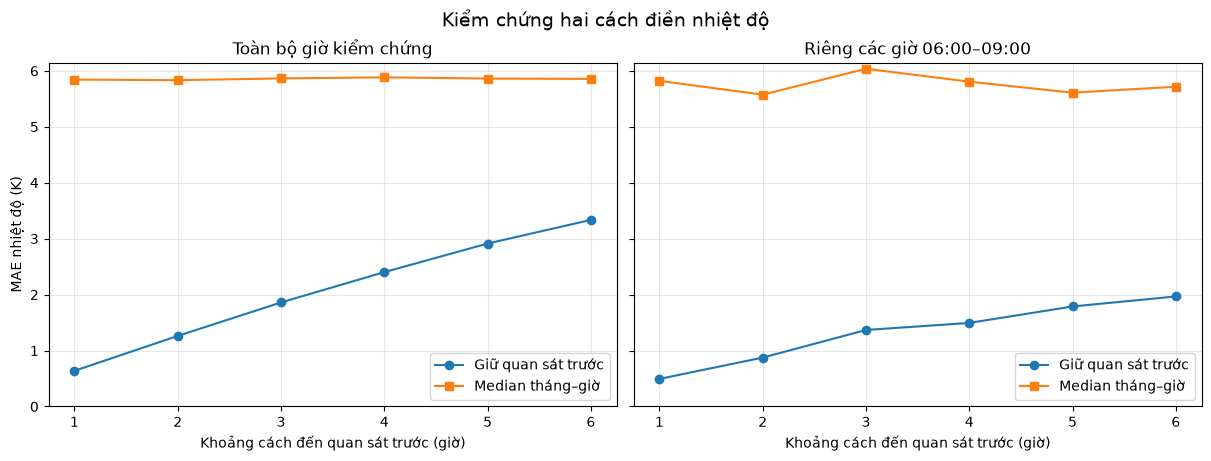

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    sharex=True,
    sharey=True,
    layout="constrained",
)

plot_tables = [
    (by_horizon, "Toàn bộ giờ kiểm chứng"),
    (morning_by_horizon, "Riêng các giờ 06:00–09:00"),
]

for ax, (table, title) in zip(axes, plot_tables):
    ax.plot(
        table.index,
        table["MAE_giu_truoc_K"],
        marker="o",
        label="Giữ quan sát trước",
    )
    ax.plot(
        table.index,
        table["MAE_median_K"],
        marker="s",
        label="Median tháng–giờ",
    )

    ax.set_title(title)
    ax.set_xlabel("Khoảng cách đến quan sát trước (giờ)")
    ax.set_xticks(range(1, 7))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("MAE nhiệt độ (K)")
fig.suptitle("Kiểm chứng hai cách điền nhiệt độ", fontsize=14)

plt.show()

### Nhận xét và quyết định về cách điền nhiệt độ

Kiểm chứng trên 776 cửa sổ, tương ứng 4.656 giờ trong giai đoạn 12/09/2016–10/05/2017, cho thấy cách giữ nhiệt độ quan sát gần nhất trước đó có MAE thấp hơn median tháng–giờ ở cả sáu khoảng cách được kiểm tra. Median được tính từ 80% đầu train, trước giai đoạn kiểm chứng.

- Trên toàn bộ giờ kiểm chứng, MAE của phương pháp giữ quan sát trước đó tăng từ khoảng 0.64 K lên 3.34 K khi khoảng thiếu tăng từ 1 đến 6 giờ.
- Riêng các giờ 06:00–09:00, MAE của phương pháp này chỉ dao động từ 0.49 K đến 1.97 K, vẫn thấp hơn đáng kể so với phương pháp median (khoảng 5.57–6.04 K).
- Sai số của phương pháp median tương đối ổn định quanh 5.8 K, trong khi sai số giữ quan sát trước đó tăng dần theo độ dài khoảng thiếu.

**Quyết định**

- Giữ quy tắc ưu tiên nhiệt độ quan sát gần nhất trước giờ thiếu nếu cách tối đa 6 giờ. Nếu không có quan sát đủ gần, dùng median tháng–giờ từ train; nếu thiếu nhóm tương ứng, dùng median nhiệt độ toàn train.
- Quy tắc đã được áp dụng trong bảng final_filled_splits. Bốn giờ thiếu ngày 31/01/2014 nhận 255,93 K và sáu giờ thiếu ngày 02/02/2014 nhận 255,37 K.
- Kết quả hỗ trợ lựa chọn này trên các cửa sổ đầy đủ đã kiểm tra, bao gồm nhóm giờ 06:00–09:00. Nhiệt độ thực của 10 giờ thiếu năm 2014 vẫn chưa được xác minh. Phép kiểm chứng cũng chưa xác định 6 giờ là ngưỡng tối ưu.

# 8. Tạo đặc trưng thời gian và đổi nhiệt độ sang °C

Tạo 5 đặt trưng giờ trong ngày, thứ trong tuần, tháng và cờ cuối tuần từ `date_time`.  
hour: 0 đến 23  
day_of_week: ( 0,1,2,3,4,5,6) 0=Thứ 2...... 6=CN  
month: 1 đến 12  
is_weekend: 1=(T7,CN), 0=Thứ ngày thường  

Đổi nhiệt độ từ Kelvin sang Celsius theo công thức `temp_c = temp - 273.15`.
Tạm giữ cả hai cột để đối chiếu công thức. Áp dụng cùng cách tạo đặc trưng
cho train, validation và test.

## Tạo năm cột mới

In [17]:
feature_splits = {}

for split_name, part in final_filled_splits.items():
    # Tạo bản sao để đối chiếu với dữ liệu trước khi thêm đặc trưng.
    featured = part.copy()
    timestamps = featured["date_time"]

    # Trích xuất đặc trưng trực tiếp từ timestamp của mỗi dòng.
    featured["hour"] = timestamps.dt.hour.astype("int8")
    featured["day_of_week"] = timestamps.dt.dayofweek.astype("int8")
    featured["month"] = timestamps.dt.month.astype("int8")
    featured["is_weekend"] = featured["day_of_week"].ge(5).astype("int8")

    # Đổi đơn vị nhiệt độ từ Kelvin sang Celsius.
    featured["temp_c"] = featured["temp"] - 273.15

    feature_splits[split_name] = featured
    print("Danh sách các tất cả cột đặt trưng khi đã thêm 5 đặt trương mới:")
print(feature_splits["train"].columns.tolist())

# Hiển thị tất cả cột trong bảng xem trước.
with pd.option_context("display.max_columns", None):
    display(feature_splits["train"].head())

Danh sách các tất cả cột đặt trưng khi đã thêm 5 đặt trương mới:
Danh sách các tất cả cột đặt trưng khi đã thêm 5 đặt trương mới:
Danh sách các tất cả cột đặt trưng khi đã thêm 5 đặt trương mới:
['date_time', 'traffic_volume', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'holiday_name', 'is_holiday', 'hour', 'day_of_week', 'month', 'is_weekend', 'temp_c']


,date_time,traffic_volume,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,holiday_name,is_holiday,hour,day_of_week,month,is_weekend,temp_c
0,2012-10-02 09:00:00,5545,288.28,0.0,0.0,40.0,clouds,scattered clouds,None,0,9,1,10,0,15.13
1,2012-10-02 10:00:00,4516,289.36,0.0,0.0,75.0,clouds,broken clouds,None,0,10,1,10,0,16.21
2,2012-10-02 11:00:00,4767,289.58,0.0,0.0,90.0,clouds,overcast clouds,None,0,11,1,10,0,16.43
3,2012-10-02 12:00:00,5026,290.13,0.0,0.0,90.0,clouds,overcast clouds,None,0,12,1,10,0,16.98
4,2012-10-02 13:00:00,4918,291.14,0.0,0.0,75.0,clouds,broken clouds,None,0,13,1,10,0,17.99


## Kiểm tra và xem ví dụ

In [18]:
new_features = ["hour", "day_of_week", "month", "is_weekend", "temp_c"]
feature_summary = []

for split_name, featured in feature_splits.items():
    original = final_filled_splits[split_name]

    # Xác nhận các cột ban đầu và thứ tự dòng được giữ nguyên.
    assert featured[original.columns].equals(original)

    # Kiểm tra miền giá trị và tính nhất quán của cờ cuối tuần.
    assert featured["hour"].between(0, 23).all()
    assert featured["day_of_week"].between(0, 6).all()
    assert featured["month"].between(1, 12).all()
    assert featured["is_weekend"].isin([0, 1]).all()
    assert featured["is_weekend"].eq(
        featured["day_of_week"].ge(5).astype("int8")
    ).all()
    assert featured[new_features].notna().all().all()

    feature_summary.append({
        "tap": split_name,
        "so_dong": len(featured),
        "so_cot": featured.shape[1],
        "temp_c_min": featured["temp_c"].min(),
        "temp_c_max": featured["temp_c"].max(),
    })

display(pd.DataFrame(feature_summary))

print("Kiểu dữ liệu của các đặc trưng mới:")
display(feature_splits["train"][new_features].dtypes)

# Ngày 02/10/2012 là thứ Ba, nên day_of_week phải bằng 1.
print("Ví dụ các dòng đầu của train:")
display(
    feature_splits["train"][
        ["date_time", "temp"] + new_features
    ].head()
)

# Xem thêm các ví dụ thứ Bảy và Chủ nhật.
print("Ví dụ cuối tuần:")
display(
    feature_splits["train"]
    .loc[
        feature_splits["train"]["is_weekend"].eq(1),
        ["date_time", "day_of_week", "is_weekend"],
    ]
    .head()
)

,tap,so_dong,so_cot,temp_c_min,temp_c_max
0,train,28402,15,-29.76,35.09
1,validation,6086,15,-27.00,33.87
2,test,6087,15,-23.92,36.92


Kiểu dữ liệu của các đặc trưng mới:


hour              int8
day_of_week       int8
month             int8
is_weekend        int8
temp_c         float64
dtype: object

Ví dụ các dòng đầu của train:


,date_time,temp,hour,day_of_week,month,is_weekend,temp_c
0,2012-10-02 09:00:00,288.28,9,1,10,0,15.13
1,2012-10-02 10:00:00,289.36,10,1,10,0,16.21
2,2012-10-02 11:00:00,289.58,11,1,10,0,16.43
3,2012-10-02 12:00:00,290.13,12,1,10,0,16.98
4,2012-10-02 13:00:00,291.14,13,1,10,0,17.99


Ví dụ cuối tuần:


,date_time,day_of_week,is_weekend
81,2012-10-06 00:00:00,5,1
82,2012-10-06 01:00:00,5,1
83,2012-10-06 02:00:00,5,1
84,2012-10-06 04:00:00,5,1
85,2012-10-06 05:00:00,5,1
